In [10]:
import pandas as pd
import numpy as np
from itertools import permutations
from statsmodels.tsa.stattools import coint
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt

In [ ]:
filepath = "Filepath to market data"
data = pd.read_parquet(filepath)

In [21]:
data.head()

,symbol,timestamp,close
0,GOOGL,2020-11-23 12:30:00+00:00,4.465908
1,GOOGL,2020-11-23 12:47:00+00:00,4.465908
2,GOOGL,2020-11-23 12:55:00+00:00,4.465908
3,GOOGL,2020-11-23 13:00:00+00:00,4.464758
4,GOOGL,2020-11-23 13:05:00+00:00,4.466023


In [22]:
data.tail()

,symbol,timestamp,close
1051372,GOOG,2024-11-20 22:37:00+00:00,5.178971
1051373,GOOG,2024-11-20 22:41:00+00:00,5.179534
1051374,GOOG,2024-11-20 22:47:00+00:00,5.179478
1051375,GOOG,2024-11-20 22:56:00+00:00,5.178463
1051376,GOOG,2024-11-21 00:00:00+00:00,5.180378


In [ ]:
# Show timestamps in New York time so the session is 09:30–16:00 year-round (handles DST)
data["timestamp"] = data["timestamp"].dt.tz_convert("America/New_York")

prices = (
    data.pivot(index="timestamp", columns="symbol", values="close")
        .between_time("09:30", "15:59") # Normalizes time to regular business hours
        .dropna()
)
prices.head()
prices["XXX"].shape

(372890,)

- score = more negative means more likely to be not cointegrated
- pvalue = Smaller value rejects null hypothesis of lack of cointegration
- crit_value = depends if 0, 1, or 2. Rejects cointegration at 99% probability if score < crit_value[0], 95% if score < crit_value[1], 90% if score < crit_value[2]

In [ ]:
score, pvalue, crit_value = coint( 
    prices["XXX"], 
    prices["XXXX"],
    trend="c",
    autolag="AIC"
)

print(f"Score: {score}")
print(f"P-value: {pvalue}")
print(f"Critical Value {crit_value}")

Score: -4.784216821408521
P-value: 0.00040233064286273815
Critical Value [-3.89646937 -3.33614639 -3.04446137]


In [25]:
if score < crit_value[0]:
    print("There is a 99% chance of cointegration!")
elif score < crit_value[1]:
    print("There is a 95% chance of cointegration!")
elif score < crit_value[2]:
    print("There is a 90% chance of cointegration!")
else:
    print("There is no statistically significant cointegration in the dataset. ")

There is a 99% chance of cointegration!


Linear Regression Test to Establish Optimal Hedge Ratio

In [ ]:
x = prices["XXX"].to_numpy()
y = prices["XXXX"].to_numpy()

In [27]:
slope, intercept = np.polyfit(x, y, deg=1)

In [28]:
y_prediction = slope * x + intercept

In [29]:
ss_res = np.sum((y-y_prediction) ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)
r_squared = 1 - ss_res/ss_tot

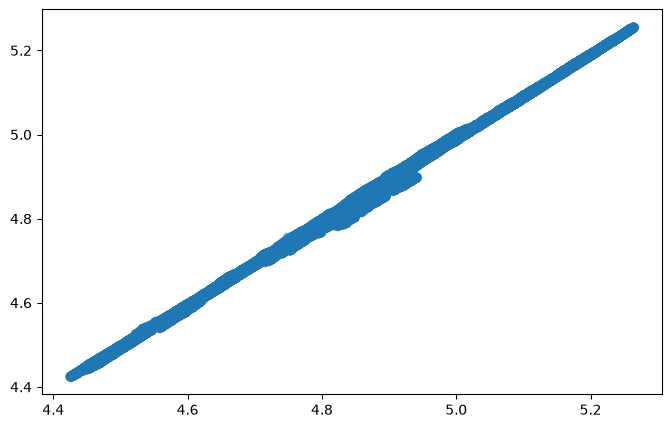

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(x, y, alpha=0.5, label="Prices of XXX vs XXXX")



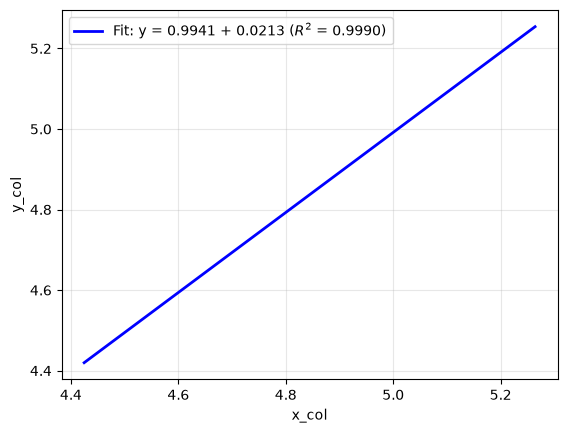

In [31]:
sort_idx = np.argsort(x)
plt.plot(
    x[sort_idx],
    y_prediction[sort_idx],
    color = "blue",
    linewidth=2,
    label = f"Fit: y = {slope:.4f} + {intercept:.4f} ($R^2$ = {r_squared:.4f})"
)
plt.xlabel("x_col")
plt.ylabel('y_col')
plt.legend()
plt.grid(True, alpha = 0.3)
plt.show()

Conclusion: GOOG and GOOGL are cointegrated!